# 09-力矩天花板


## 1. 本课目标：控制指令也有上限

本篇对应《具身智能机器人实战》第 09 节《力矩天花板》，副标题为 `control range`。上一节用 PD 控制把位置和速度误差转换成力矩，本节强调：控制器算出的数值，还必须符合执行器的输出能力。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/09_力矩天花板.pptx` 全部 3 页：第 1 页为标题，第 2 页用电机与卡车说明能力限制，第 3 页为品牌结束页。

课件没有给出 T800 的具体力矩范围、XML 配置或限幅代码。第 3、4 节据官方模型和 MuJoCo 文档作必要的工程补充。未转录配套视频 `09_力矩范围.mp4`，也未读取网盘中的 `code.zip`。


## 2. 电机为什么不能想出多大力就出多大力

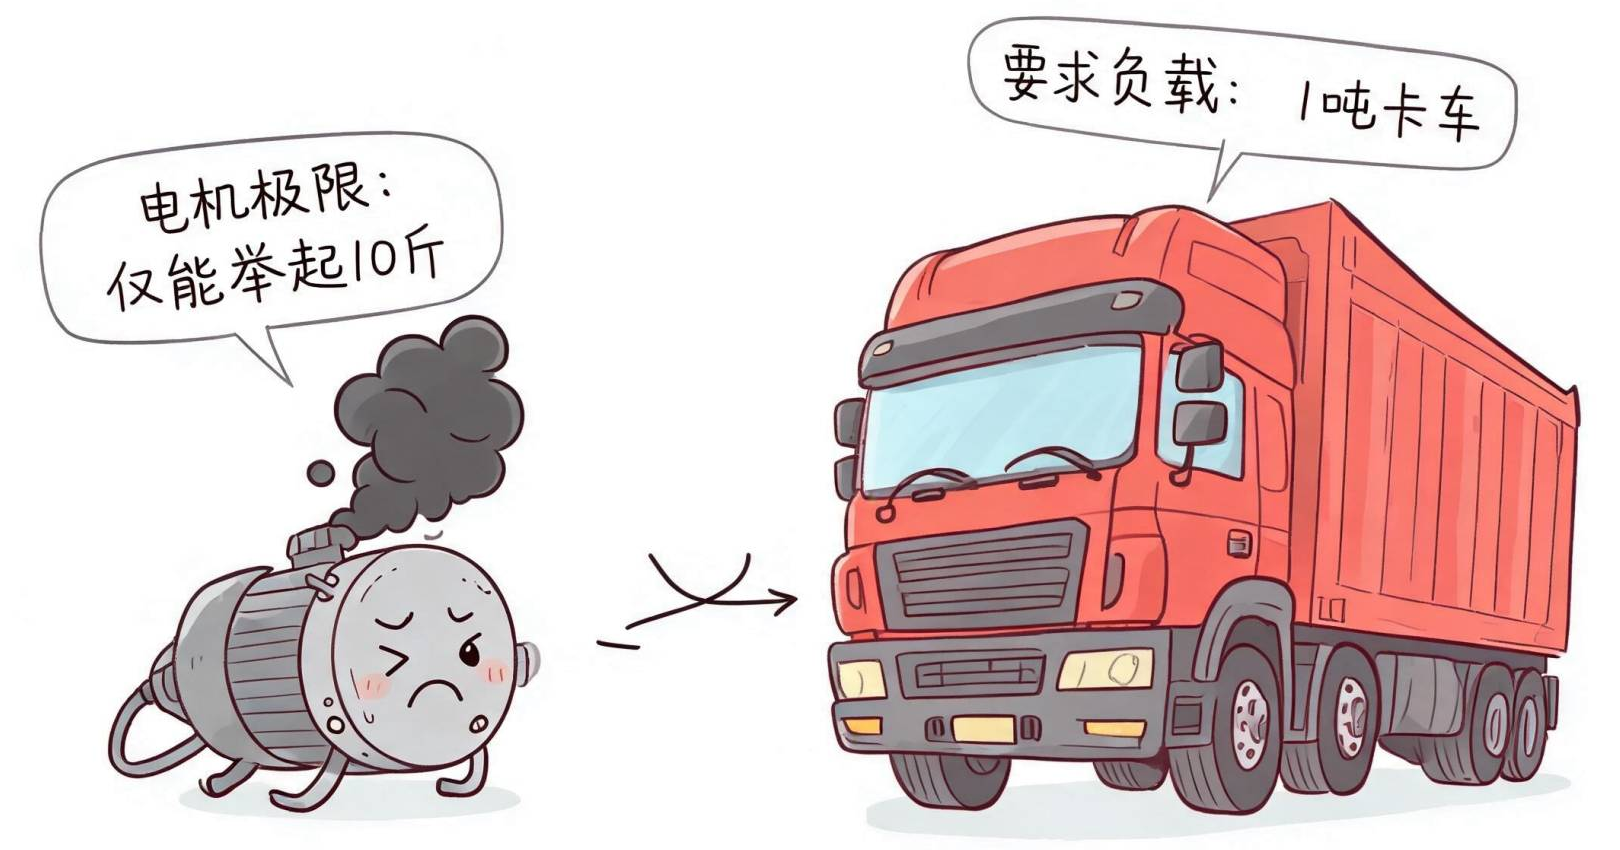

*原课件第 2 页：电机“仅能举起 10 斤”，要求的负载却是“1 吨卡车”。*

这张图强调负载要求与电机能力之间的差距。即使控制器要求更大的输出，电机也有自己的能力边界，不能因为目标很远、误差很大，就无限增大实际输出。

接到上一节的 PD 控制：位置误差增大或增益调高时，计算出的力矩可能超过执行器允许的范围。此时需要给控制输入设置上、下限，超过上限就取上限，低于下限就取下限。这种处理称为**限幅**；指令超过能力边界时，也常说输出进入了饱和状态。

> 力矩限幅约束本步能施加多大的驱动作用，并不保证电机一定能完成目标动作。负载需求超过能力时，关节仍可能到不了目标。

**工程补充：**图中的“斤”和“吨”用于负载类比，不是力矩单位。转动关节的力矩通常以 N·m 表示，还与受力大小、力臂和姿态有关，不能把“10 斤”直接换成某个 T800 关节的力矩上限。图中的冒烟也是示意，不能据此认为当前仿真模型已经包含电机温升或烧毁过程。


## 3. 工程补充：读取模型已有的控制范围

沿用第 03 篇引入的官方 T800 模型。本篇核对的提交为 `335c60e88772c26c7852d0abd6b3c7439037dd8f`。在该仓库的 `assets/resource/robot/t800/xml/serial_actuators.xml` 中，右肩俯仰执行器配置为：

```xml
<motor name="motor_J18_SHOULDER_PITCH_R"
       joint="J18_SHOULDER_PITCH_R"
       gear="1" ctrllimited="true" ctrlrange="-160 160" />
```

`ctrllimited="true"` 启用控制输入限幅，`ctrlrange` 给出下限与上限。模型加载后，分别从 `model.actuator_ctrllimited[actuator_id]` 和 `model.actuator_ctrlrange[actuator_id]` 查询，不必在控制代码里再手写一套范围。

本例是直接驱动单轴转动关节的 `motor`，固定增益为 1、无偏置，且 `gear="1"`，所以限幅后的输入可按该关节的 N·m 力矩解释。正负号表示沿关节轴的两个作用方向。其他执行器的输入含义要结合类型和传动配置判断。

这里的 `[-160, 160]` 是这个版本模型的配置。不同执行器可以有不同范围，例如同版本左髋俯仰 motor 为 `[-415, 415]`，右肘偏航 motor 为 `[-52, 52]`。这些数值不是课件给出的实机规格，不能统一套成 `±160`。

### 3.1 不同的 range 限制不同的量

| 配置位置与字段 | 限制对象 |
|---|---|
| 执行器 `ctrllimited`、`ctrlrange` | 送入执行器的控制输入 |
| 执行器 `forcelimited`、`forcerange` | 单个执行器输出的标量力，再经传动映射到关节 |
| 关节 `actuatorfrclimited`、`actuatorfrcrange` | 作用于该单轴关节的执行器合力或合力矩 |
| 关节 `limited`、`range` | 关节的位置范围，例如转动角度 |

同版本的 `serial_links.xml` 还为右肩俯仰关节设置了 `actuatorfrcrange="-160 160"`。编译后的关节执行器力矩限制已启用；该 motor 自身的 `forcelimited` 则未启用。这里控制输入与关节合力矩的边界数值相同，但它们位于不同环节，含义仍需分清。

以下示例使用模型默认的全局选项，控制输入限幅未被全局关闭。只看到 XML 中有 `ctrlrange`，还应核对对应限幅是否实际生效。


## 4. 工程补充：观察限幅，再接回 PD 主循环

### 4.1 核对引擎怎样处理超出范围的输入

沿用前几篇的 `t800-load` 目录、官方模型和 `.venv`，新建 `torque_range_t800.py`。下面故意写入三个测试指令，用来观察引擎内部限幅；这三个值不代表 PD 调参结果。

```python
import argparse
from pathlib import Path

import mujoco
import numpy as np


parser = argparse.ArgumentParser(description="T800 控制范围检查")
parser.add_argument(
    "--model", type=Path,
    default=Path(__file__).resolve().parent
    / "engineai_robotics_native_sdk/assets/resource/t800.xml",
)
args = parser.parse_args()
model = mujoco.MjModel.from_xml_path(str(args.model.expanduser().resolve()))
data = mujoco.MjData(model)

joint_id = model.joint("J18_SHOULDER_PITCH_R").id
qpos_index = int(model.jnt_qposadr[joint_id])
qvel_index = int(model.jnt_dofadr[joint_id])
actuator_id = model.actuator("motor_J18_SHOULDER_PITCH_R").id
if not model.actuator_ctrllimited[actuator_id]:
    raise RuntimeError("该执行器未启用控制输入限幅")
lo, hi = model.actuator_ctrlrange[actuator_id]
print(f"ctrlrange=[{lo:.0f}, {hi:.0f}]")

for requested in (250.0, -250.0, 50.0):
    mujoco.mj_resetData(model, data)
    data.ctrl[actuator_id] = requested
    mujoco.mj_forward(model, data)
    print(
        f"requested={requested:.0f}, ctrl={data.ctrl[actuator_id]:.0f}, "
        f"actuator_force={data.actuator_force[actuator_id]:.0f}, "
        f"joint_torque={data.qfrc_actuator[qvel_index]:.0f}"
    )
```

在 `t800-load` 目录的 PowerShell 中执行：

```powershell
.\.venv\Scripts\python.exe torque_range_t800.py
```

模型在其他位置时，可用 `--model` 指定完整资源目录中的场景入口。本篇在 MuJoCo 3.4.0 与上述官方模型上实际运行，得到：

```text
ctrlrange=[-160, 160]
requested=250, ctrl=250, actuator_force=160, joint_torque=160
requested=-250, ctrl=-250, actuator_force=-160, joint_torque=-160
requested=50, ctrl=50, actuator_force=50, joint_torque=50
```

`mj_forward()` 根据当前状态重新计算动力学量，不推进仿真时间。结果表明：超范围输入在执行器计算时受限，但 `data.ctrl` 数组仍保留写入的 `250` 或 `-250`。因此，不能只看 `data.ctrl` 就断言关节实际获得了这么大的力矩。

这里 `actuator_force` 是执行器的标量输出，`qfrc_actuator` 是映射到广义速度坐标后的执行器合力。本模型对该关节只有一个 `gear=1` 的 motor，因此两者在这些测试中数值相等；`qfrc_actuator` 不包含重力、接触等全部作用力。

### 4.2 在写入 ctrl 前显式限幅

把 PD 的原始结果记为 $\tau_{\mathrm{raw}}$，下、上限记为 $\tau_{\min}$、$\tau_{\max}$，则：

$$
\tau_{\mathrm{cmd}}=\min\!\left(\max(\tau_{\mathrm{raw}},\tau_{\min}),\tau_{\max}\right)
$$

`np.clip()` 就能完成这个操作。把下面代码接在上述脚本末尾，使用同一个模型和已经查询到的下标、范围。它延续第 08 篇的目标 `0.1 rad`、`Kp=20`、`Kd=2`，每一步重新计算 PD，再限幅、写入输入、推进物理仿真：

```python
mujoco.mj_resetData(model, data)
mujoco.mj_forward(model, data)
target = 0.1
kp, kd = 20.0, 2.0

for _ in range(100):
    q = float(data.qpos[qpos_index])
    dq = float(data.qvel[qvel_index])
    tau_raw = kp * (target - q) - kd * dq
    tau_cmd = float(np.clip(tau_raw, lo, hi))
    data.ctrl[:] = 0.0
    data.ctrl[actuator_id] = tau_cmd
    mujoco.mj_step(model, data)
```

显式限幅使写入 `data.ctrl` 的值就处于配置范围内，也便于分别记录原始需求 `tau_raw` 与实际提交的 `tau_cmd`。限幅放在 P、D 两项相加之后，约束最终提交的总指令。

这组 PD 参数在本次 100 步运行中没有触发限幅，第一次原始指令为 `2 N·m`；运行结束时仿真时间为 `0.200 s`。前面的 `±250` 测试才用于核对超范围情况。两部分都已实际运行，状态数值有限且没有 MuJoCo 警告；未打开图形查看器，也未验证整机站立或实机控制效果。


## 5. 本课检查与补充参考

完成本节，应能说明负载要求与电机能力的区别，找到目标执行器已有的控制范围，并在 PD 总指令写入 `ctrl` 前限幅。还应能区分控制输入范围、执行器输出范围与关节位置范围，知道引擎内部限幅不一定改写 `data.ctrl`。

持续达到上限意味着控制器需要的驱动作用超过当前允许值。继续提高增益不能突破这个边界，限幅本身也不能证明关节一定到达目标或系统已经稳定。

- [本篇版本的 T800 motor 配置](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_actuators.xml)。
- [同版本的关节配置](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_links.xml)。
- [MuJoCo 3.4.0：控制输入限幅](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#actuator-general-ctrllimited)。
- [MuJoCo 3.4.0：单个执行器输出范围](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#actuator-general-forcerange)。
- [MuJoCo 3.4.0：关节执行器合力范围](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#body-joint-actuatorfrcrange)。
